# Quantum SVM — Bars and Stripes

Misma estructura que `QSVM_Iris` (ZZFeatureMap + kernel de fidelidad), sobre Bars and Stripes con PCA→4 qubits.


## Librerias


In [1]:
# 1. Import all libraries
import json
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from pennylane.data import Dataset
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

np.random.seed(123)


## Data

Imágenes oficiales PennyLane (`4×4` → 16 features). Carga lazy del `.h5`.


In [2]:
DATASET_URL = (
    "https://datasets.cloud.pennylane.ai/datasets/h5/"
    "other/BarsAndStripes/BarsAndStripes_BarsAndStripes.h5"
)
IMAGE_SIZE = "4"  # 4x4 pixels -> 16 features


def resolve_dataset_path() -> Path:
    """Busca el .h5 en caches locales tipicos de PennyLane."""
    candidates = []
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        candidates.append(
            base / "datasets" / "other" / "BarsAndStripes" / "BarsAndStripes_BarsAndStripes.h5"
        )
    for path in candidates:
        if path.is_file():
            return path
    return candidates[0]


def ensure_bars_and_stripes(path: Path | None = None) -> Path:
    path = resolve_dataset_path() if path is None else Path(path)
    if path.is_file():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading PennyLane bars-and-stripes -> {path} (one-time, ~750MB)")
    urllib.request.urlretrieve(DATASET_URL, path)
    return path


def load_bars_and_stripes(image_size: str = IMAGE_SIZE):
    path = ensure_bars_and_stripes()
    ds = Dataset.open(path, "r")
    try:
        X_train = np.asarray(ds.train[image_size]["inputs"], dtype=float)
        y_train = np.asarray(ds.train[image_size]["labels"], dtype=float)
        X_test = np.asarray(ds.test[image_size]["inputs"], dtype=float)
        y_test = np.asarray(ds.test[image_size]["labels"], dtype=float)
    finally:
        ds.close()
    return X_train, y_train, X_test, y_test


print("Loading PennyLane 'bars-and-stripes' (image_size=4)...")
X_train_official, y_train_official, X_test_official, y_test_official = load_bars_and_stripes(IMAGE_SIZE)
print(
    f"Official splits -> train: {X_train_official.shape}, test: {X_test_official.shape}"
)
print("Label values (train):", np.unique(y_train_official, return_counts=True))


Loading PennyLane 'bars-and-stripes' (image_size=4)...
Official splits -> train: (1000, 16), test: (200, 16)
Label values (train): (array([-1.,  1.]), array([514, 486]))


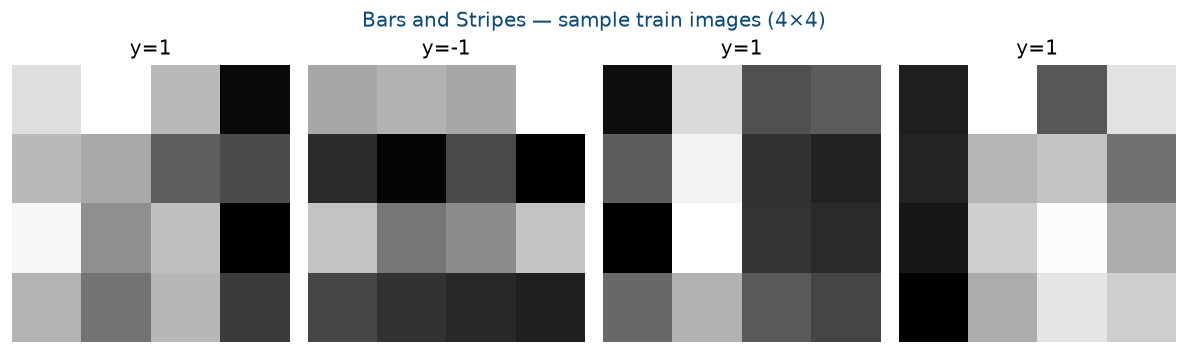

In [3]:
# Preview: first samples as 4x4 images + label
fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=120)
for i, ax in enumerate(axs):
    ax.imshow(X_train_official[i].reshape(4, 4), cmap="gray")
    ax.set_title(f"y={int(y_train_official[i])}")
    ax.axis("off")
fig.suptitle("Bars and Stripes — sample train images (4×4)", color="#0E4A75")
plt.tight_layout()
plt.show()


## Data Preparation

Protocolo Iris + **PCA a 4 componentes** para el feature map de 4 qubits.


In [4]:
# Combine official splits, map labels, Iris protocol + PCA->4 qubits
X = np.concatenate([X_train_official, X_test_official], axis=0)
y = np.concatenate([y_train_official, y_test_official], axis=0)
y = np.where(y <= 0, 0, 1).astype(int)

n_qubits = 4
print(f"Combined dataset: n={len(X)}, features={X.shape[1]}, classes={np.unique(y, return_counts=True)}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)
print(f"Custom Dataset Loaded: Train={len(X_train_raw)}, Test={len(X_test_raw)}")

pca = PCA(n_components=n_qubits, random_state=123)
X_train_pca = pca.fit_transform(X_train_raw)
X_test_pca = pca.transform(X_test_raw)
print(f"PCA explained variance ratio sum: {pca.explained_variance_ratio_.sum():.4f}")

minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(X_train_pca)
X_test = minmax.transform(X_test_pca)
X_test = np.clip(X_test, 0, np.pi)
n_features = X_train.shape[1]
print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")


Combined dataset: n=1200, features=16, classes=(array([0, 1]), array([625, 575]))
Custom Dataset Loaded: Train=720, Test=480
PCA explained variance ratio sum: 0.5753
Final shapes -> Train: (720, 4), Test: (480, 4)


## Quantum SVM


### Physical Point to Quantum State


In [5]:
# QSVM con ZZFeatureMap de Qiskit
feature_map = zz_feature_map(
    feature_dimension=n_qubits,
    reps=2,
    entanglement="full",
)
quantum_kernel = FidelityStatevectorKernel(feature_map=feature_map)

class FastQSVM:
    def __init__(self):
        self.svm = SVC(kernel=quantum_kernel.evaluate, random_state=42)

    def fit(self, X, y):
        self.svm.fit(X, y)
        return self

    def predict(self, X):
        return self.svm.predict(X)

    def decision_function(self, X):
        return self.svm.decision_function(X)


## Entrenamiento QSVM


In [6]:
# Training and timing statistics
print("=== Train QSVM ===")
qsvm_model = FastQSVM()
start = time.time()
qsvm_model.fit(X_train, y_train)
qsvm_time = time.time() - start
print(f"QSVM training time: {qsvm_time:.2f}s")


=== Train QSVM ===
QSVM training time: 1.43s


## Model Evaluation


In [7]:
def evaluate(model, X_t, y_t, classes):
    preds = model.predict(X_t)
    scores = model.decision_function(X_t)

    acc = accuracy_score(y_t, preds)
    prec = precision_score(y_t, preds, average="macro", zero_division=0)
    rec = recall_score(y_t, preds, average="macro", zero_division=0)
    f1 = f1_score(y_t, preds, average="macro", zero_division=0)
    if np.ndim(scores) == 1:
        auc = roc_auc_score(y_t, scores)
    else:
        auc = roc_auc_score(
            label_binarize(y_t, classes=classes), scores, average="macro", multi_class="ovr"
        )
    return acc, prec, rec, f1, auc, scores, preds


In [8]:
classes = np.unique(y_train)

qsvm_acc, qsvm_prec, qsvm_rec, qsvm_f1, qsvm_auc, qsvm_probs, qsvm_preds = evaluate(
    qsvm_model, X_test, y_test, classes
)
qsvm_acc_tr, qsvm_prec_tr, qsvm_rec_tr, qsvm_f1_tr, qsvm_auc_tr, _, _ = evaluate(
    qsvm_model, X_train, y_train, classes
)

print("\n=== Train vs Test ===")
print(
    f"QSVM Train - Acc: {qsvm_acc_tr:.4f} | Prec: {qsvm_prec_tr:.4f} | Rec: {qsvm_rec_tr:.4f} | "
    f"F1: {qsvm_f1_tr:.4f} | AUC: {qsvm_auc_tr:.4f}"
)
print(
    f"QSVM Test  - Acc: {qsvm_acc:.4f} | Prec: {qsvm_prec:.4f} | Rec: {qsvm_rec:.4f} | "
    f"F1: {qsvm_f1:.4f} | AUC: {qsvm_auc:.4f}"
)



=== Train vs Test ===
QSVM Train - Acc: 0.8681 | Prec: 0.8678 | Rec: 0.8683 | F1: 0.8679 | AUC: 0.9404
QSVM Test  - Acc: 0.7583 | Prec: 0.7588 | Rec: 0.7591 | F1: 0.7583 | AUC: 0.8218


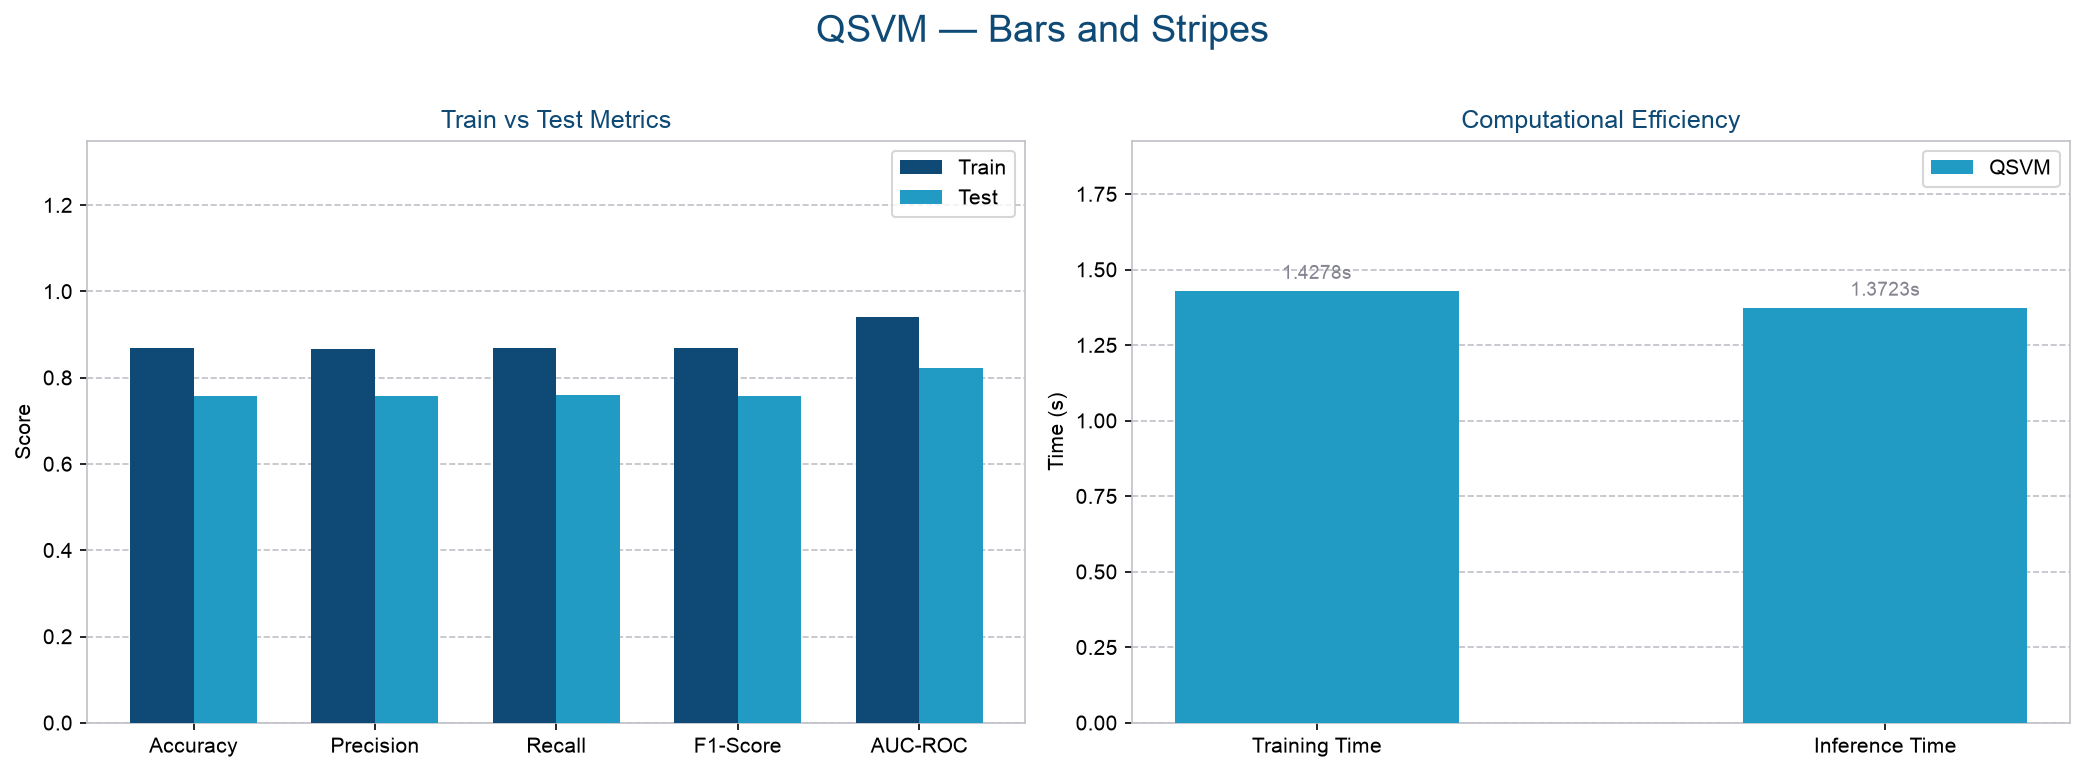

In [9]:
# Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    "font.sans-serif": ["Arial"],
    "axes.edgecolor": "#C0C0C8",
    "grid.color": "#C0C0C8",
    "grid.linestyle": "--",
})

def get_inference_time(model, data):
    start = time.time()
    _ = model.predict(data)
    return time.time() - start

qsvm_inf_time = get_inference_time(qsvm_model, X_test)

train_color = "#0E4A75"
test_color = "#219BC3"
unir_gris = "#858591"

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle("QSVM — Bars and Stripes", fontsize=18, y=1.02, color="#0E4A75")

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
train_vals = [qsvm_acc_tr, qsvm_prec_tr, qsvm_rec_tr, qsvm_f1_tr, qsvm_auc_tr]
test_vals = [qsvm_acc, qsvm_prec, qsvm_rec, qsvm_f1, qsvm_auc]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width / 2, train_vals[i], width, color=train_color,
               label="Train" if i == 0 else "", zorder=3)
    axs[0].bar(x[i] + width / 2, test_vals[i], width, color=test_color,
               label="Test" if i == 0 else "", zorder=3)

axs[0].set_ylabel("Score")
axs[0].set_title("Train vs Test Metrics", color="#0E4A75")
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc="upper right")
axs[0].grid(axis="y", zorder=0)

eff_labels = ["Training Time", "Inference Time"]
eff = [qsvm_time, qsvm_inf_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, eff, 0.5, color="#219BC3", label="QSVM", zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel("Time (s)")
axs[1].set_title("Computational Efficiency", color="#0E4A75")
max_time = max(eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc="upper right")
axs[1].grid(axis="y", zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], eff[i] + offset, f"{eff[i]:.4f}s",
                ha="center", va="bottom", fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [10]:
# Save metrics for BSClassification comparison
import json
from pathlib import Path
import sys

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "case_paths.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/case_paths.py not found")

import importlib
import case_paths as _case_paths
importlib.reload(_case_paths)
from case_paths import resolve_metrics_dir as _resolve_metrics_dir

def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/Classification/BSClassification/metrics (helper compartido)."""
    return _resolve_metrics_dir("Classification", "BSClassification")

metrics_dir = resolve_metrics_dir()



payload = {
    "model": "QSVM",
    "family": "quantum",
    "protocol": {
        "dataset": "bars-and-stripes",
        "image_size": int(IMAGE_SIZE),
        "n_features": int(n_features),
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
        "labels": "mapped {-1,1}->{0,1}",
        "pca": "PCA(n_components=4)",
        "n_qubits": 4,
    },
    "train": {
        "accuracy": float(qsvm_acc_tr),
        "precision": float(qsvm_prec_tr),
        "recall": float(qsvm_rec_tr),
        "f1": float(qsvm_f1_tr),
        "auc": float(qsvm_auc_tr),
    },
    "test": {
        "accuracy": float(qsvm_acc),
        "precision": float(qsvm_prec),
        "recall": float(qsvm_rec),
        "f1": float(qsvm_f1),
        "auc": float(qsvm_auc),
    },
    "train_time_s": float(qsvm_time),
    "inference_time_s": float(qsvm_inf_time),
}

out = metrics_dir / "qsvm_bs.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/metrics/qsvm_bs.json


## Storytelling plots

`figures/`: PCA sin frontera + con frontera del **mismo** modelo ya entrenado.
Puntos test usan `*_preds` del notebook; la malla usa `modelo.predict` (sin reentrenar).


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/figures/qsvm_bs_samples.png


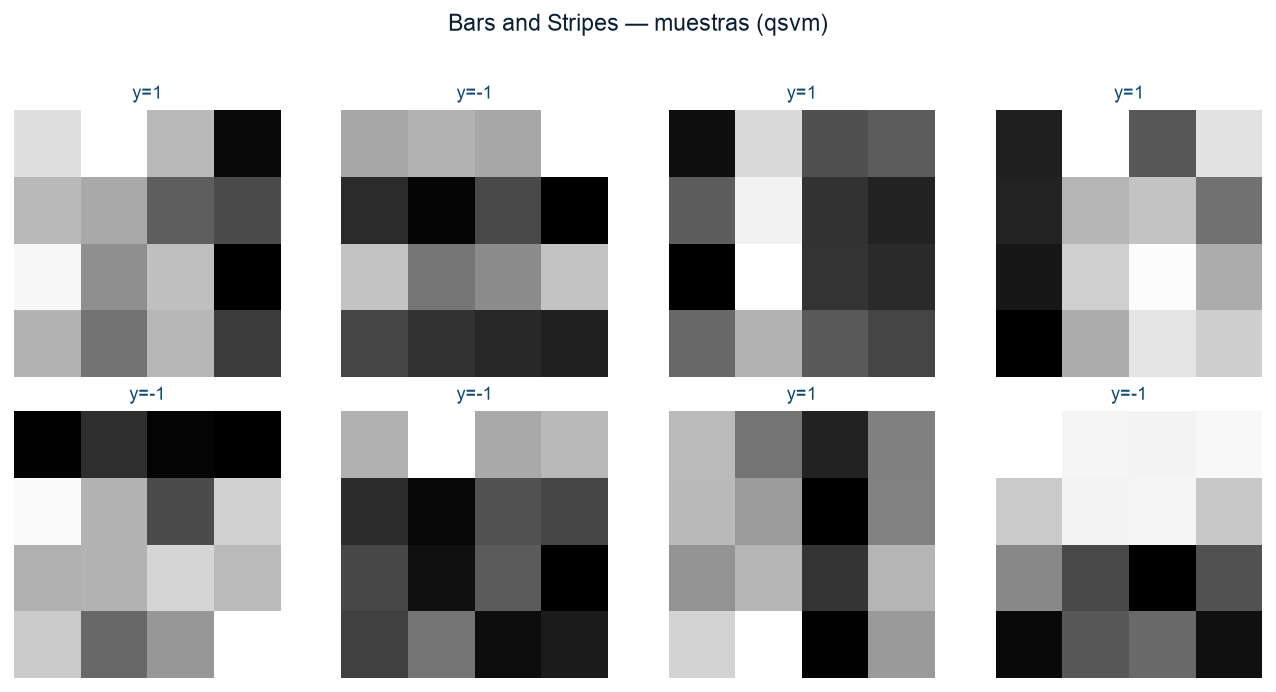

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/figures/qsvm_bs_pca_scatter.png


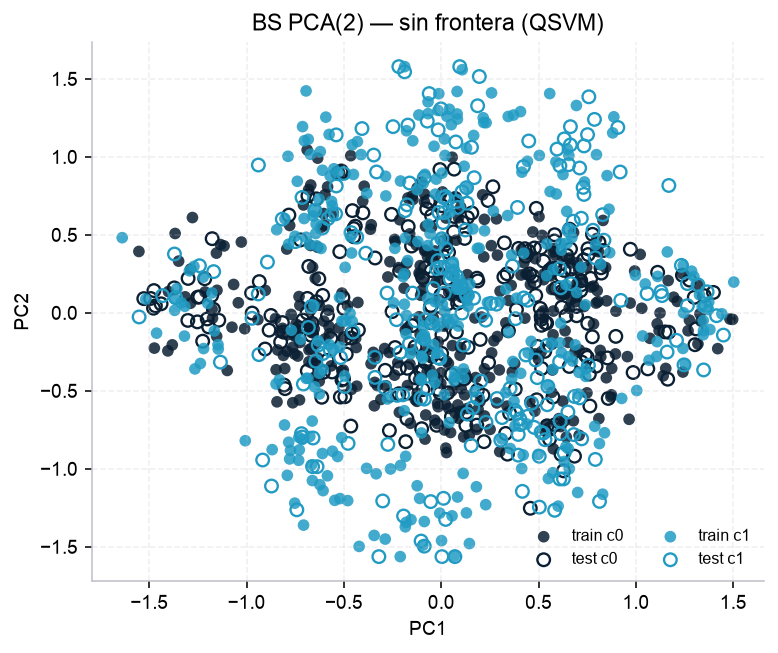

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/figures/qsvm_bs_pca_boundary.png


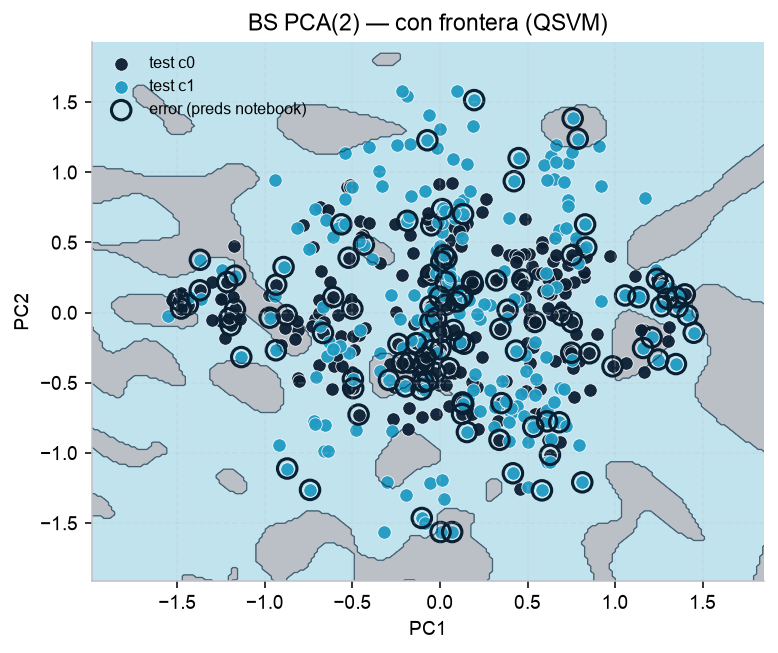

In [11]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import resolve_figures_dir, plot_bs_samples, plot_bs_pca_story

figures_dir = resolve_figures_dir("Classification", "BSClassification")
predict_fn = qsvm_model.predict
_imgs = X_train_official if "X_train_official" in globals() else (X_train_raw if "X_train_raw" in globals() else None)
_labs = y_train_official if "y_train_official" in globals() else y_train
if _imgs is not None:
    plot_bs_samples(_imgs, _labs, figures_dir, stem="qsvm", n_show=8)
plot_bs_pca_story(
    X_train, y_train, X_test, y_test,
    y_pred_test=qsvm_preds,
    predict_fn=predict_fn,
    figures_dir=figures_dir,
    stem="qsvm",
    title_model="QSVM",
)

plt.show()
